<br>
<font>
<div dir=ltr align=center>
<font color=0F5298 size=7>
    System 2 - Homework 3<br>
<font color=2565AE size=5>
    Spring 2025<br>
<font color=3C99D size=5>
    Graph RAG <br>

*`Full Name:`* Farzan Rahmani

*`SID:`* 403210725


----




In this Notebook, we'll explore the implementation of the GraphRAG (Graph-based Retrieval-Augmented Generation) approach to query-focused summarization, as described in the research paper `"From Local to Global: A GraphRAG Approach to Query-Focused Summarization"` by Darren Edge et al. This method is designed to generate comprehensive and diverse answers to global questions over entire text corpora by leveraging a graph-based text index and an LLM (Large Language Model).

We'll walk through a Python-based implementation that includes key steps from the paper, demonstrating how to process documents, build a graph, detect communities, and generate a final answer to a query.

Overview of the proposed Pipeline:
![GraphRAG](https://drive.google.com/uc?export=view&id=16Pv1vt_yY6u9ARodmnkbRmQttcpnjB18)

In [3]:
!pip install -q networkx leidenalg cdlib python-igraph pypdf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 50.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 263.6/263.6 kB 20.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 304.2/304.2 kB 25.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.4/16.4 MB 64.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 161.7/161.7 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 79.9 MB/s eta 0:00:00


In [4]:
from cdlib import algorithms

Note: to be able to use all crisp methods, you need to install some additional packages:  {'graph_tool', 'infomap', 'bayanpy'}
Note: to be able to use all crisp methods, you need to install some additional packages:  {'pyclustering', 'ASLPAw'}
Note: to be able to use all crisp methods, you need to install some additional packages:  {'infomap'}


In [5]:
%%capture --no-stderr
!pip install langchain-opentutorial

In [6]:
from langchain_opentutorial import package

package.install(
    [
        "langchain_core",
        "langchain_community",
        "langchain-graphrag",
    ],
    verbose=False,
    upgrade=False,
)

In [7]:
# Download and save sample PDF file to ./data directory
import requests
import os

def download_pdf(url, save_path):
    """
    Downloads a PDF file from the given URL and saves it to the specified path.

    Args:
        url (str): The URL of the PDF file to download.
        save_path (str): The full path (including file name) where the file will be saved.
    """
    try:
        # Ensure the directory exists
        os.makedirs(os.path.dirname(save_path), exist_ok=True)

        # Download the file
        response = requests.get(url, stream=True)
        response.raise_for_status()  # Raise an error for bad status codes

        # Save the file to the specified path
        with open(save_path, "wb") as file:
            for chunk in response.iter_content(chunk_size=8192):
                file.write(chunk)

        print(f"PDF downloaded and saved to: {save_path}")
    except Exception as e:
        print(f"An error occurred while downloading the file: {e}")

# Configuration for the PDF file
pdf_url = "https://arxiv.org/pdf/2404.16130v1"
file_path = "./data/2404.16130v1.pdf"

# Download the PDF
download_pdf(pdf_url, file_path)

# Load the GraphRAG paper using PyPDFLoader.
# PyPDFLoader loads PDF content on a per-page basis.
from langchain.document_loaders import PyPDFLoader

loader = PyPDFLoader(file_path)
docs = loader.load()
print(f"Loaded {len(docs)} documents.")
print(docs[0].page_content)

PDF downloaded and saved to: ./data/2404.16130v1.pdf
Loaded 15 documents.
From Local to Global: A Graph RAG Approach to
Query-Focused Summarization
Darren Edge1† Ha Trinh1† Newman Cheng2 Joshua Bradley2 Alex Chao3
Apurva Mody3 Steven Truitt2
Jonathan Larson1
1Microsoft Research
2Microsoft Strategic Missions and Technologies
3Microsoft Office of the CTO
{daedge,trinhha,newmancheng,joshbradley,achao,moapurva,steventruitt,jolarso}
@microsoft.com
†These authors contributed equally to this work
Abstract
The use of retrieval-augmented generation (RAG) to retrieve relevant informa-
tion from an external knowledge source enables large language models (LLMs)
to answer questions over private and/or previously unseen document collections.
However, RAG fails on global questions directed at an entire text corpus, such
as “What are the main themes in the dataset?”, since this is inherently a query-
focused summarization (QFS) task, rather than an explicit retrieval task. Prior
QFS methods, meanwhile

In [ ]:
# ValueError: numpy.dtype size changed, may indicate binary incompatibility. Expected 96 from C header, got 88 from PyObject
# !pip install -q --upgrade pandas pandasai

In [8]:
from langchain_core.documents import Document
from langchain_graphrag.indexing import TextUnitExtractor
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(chunk_size=600, chunk_overlap=100)
text_unit_extractor = TextUnitExtractor(text_splitter=splitter)

# This runs the text splitting logic on the loaded PDF pages
df_text_units = text_unit_extractor.run(docs)
df_text_units

Extracting text units ...: 100%|██████████| 6/6 [00:00<00:00, 25864.16it/s]

Extracting text units ...: 100%|██████████| 8/8 [00:00<00:00, 30897.27it/s]

Extracting text units ...: 100%|██████████| 7/7 [00:00<00:00, 56789.42it/s]

Extracting text units ...: 100%|██████████| 9/9 [00:00<00:00, 73584.28it/s]

Extracting text units ...: 100%|██████████| 7/7 [00:00<00:00, 53188.64it/s]

Extracting text units ...: 100%|██████████| 8/8 [00:00<00:00, 59283.45it/s]

Extracting text units ...: 100%|██████████| 9/9 [00:00<00:00, 74308.54it/s]

Extracting text units ...: 100%|██████████| 10/10 [00:00<00:00, 66576.25it/s]

Extracting text units ...: 100%|██████████| 8/8 [00:00<00:00, 65408.25it/s]

Extracting text units ...: 100%|██████████| 9/9 [00:00<00:00, 72593.72it/s]

Extracting text units ...: 100%|██████████| 9/9 [00:00<00:00, 74749.97it/s]

Extracting text units ...: 100%|██████████| 8/8 [00:00<00:00, 53515.84it/s]

Extracting text units ...: 100%|██████████| 8/8 [00:00<00:00, 66313.11it/s

,document_id,id,text_unit
0,d994bbf2-3b28-40fa-a3aa-d8f7f282a967,a1a0a792-abeb-4924-92aa-48bf39ee9329,From Local to Global: A Graph RAG Approach to\...
1,d994bbf2-3b28-40fa-a3aa-d8f7f282a967,c92ab328-aac1-45c4-96a6-ad2d36c4578e,tion from an external knowledge source enables...
2,d994bbf2-3b28-40fa-a3aa-d8f7f282a967,93890e48-a4b0-41ff-9f87-af60f52eada9,RAG systems. To combine the strengths of these...
3,d994bbf2-3b28-40fa-a3aa-d8f7f282a967,cb8fdb79-63a6-4ab7-b4a6-612d107aa39d,"question, each community summary is used to ge..."
4,d994bbf2-3b28-40fa-a3aa-d8f7f282a967,e49b8fc0-8ecf-486e-8a67-2538014992ca,approaches is forthcoming at https://aka.ms/gr...
...,...,...,...
110,2ebed197-a919-42e2-b75d-2b44d00999b5,b0caa493-7f7a-43d2-baf3-fcd4966c9b65,well-connected communities. Scientific Reports...
111,2ebed197-a919-42e2-b75d-2b44d00999b5,9533f8bb-5b14-4e01-ba05-f9aaaed0a25b,a good nlg evaluator? a preliminary study. arX...
112,2ebed197-a919-42e2-b75d-2b44d00999b5,4bb9b7b5-1fd3-4cb8-912e-5161853c3937,"arXiv:2106.00104.\nYang, Z., Qi, P., Zhang, S...."
113,ce0a73d1-0082-4eb4-8ced-9fc8a29adcfe,497371d9-7fac-4bed-a2e6-3a16815d90ef,"Yao, L., Peng, J., Mao, C., and Luo, Y . (2023..."


In [1]:
from transformers import AutoModelForCausalLM, AutoTokenizer
import networkx as nx
from cdlib import algorithms
import os

model_name = "Qwen/Qwen3-4B"

# load the tokenizer and the model
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype="auto",
    device_map="auto"
)

def get_response(prompt, content):
    messages = [
        {"role": "user", "content": content + ' Do not include any additional and irrelevant information. \t' + prompt}
    ]
    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False # Switches between thinking and non-thinking modes. Default is True.
    )
    model_inputs = tokenizer([text], return_tensors="pt").to(model.device)

    generated_ids = model.generate(
        **model_inputs,
        max_new_tokens=32768
    )
    output_ids = generated_ids[0][len(model_inputs.input_ids[0]):].tolist()

    # duplicate code :)
    # generated_ids = model.generate(
    #     **model_inputs,
    #     max_new_tokens=32768
    # )
    # output_ids = generated_ids[0][len(model_inputs.input_ids[0]):].tolist()

    response = tokenizer.decode(output_ids[0:], skip_special_tokens=True).strip("\n")
    return response

get_response('hi', '')

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

... (3 outputs left out)

model-00003-of-00003.safetensors:   0%|          | 0.00/99.6M [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

'hi'

`1. Text Chunks → Element Instances`

  First, we'll extract entities and relationships from each chunk of text using Qwen

In [9]:
def extract_element_Instances(chunks):
    """
      Inputs:
        chunks (list of str): List of text chunks.
      Output:
        List of extracted elements (entity-relationship data).
    """
    elements = []
    for index, chunk in enumerate(chunks):
        ############### Your Code - 5pts #############################
        print(f"Chunk index {index} of {len(chunks)}:")
        # TODO
#         content = """You are an information-extraction assistant. Extract entities and relationships from the provided text. Format your response as:

# **Entities:**
# - Entity1
# - Entity2
# - ...

# **Relationships:**
# - Entity1 relationship Entity2
# - Entity3 relationship Entity4
# - ...

# Be precise and identify key concepts, people, organizations, methods, and their relationships."""

        # content = (
        #     "You are an information-extraction assistant. "
        #     "From the text that follows, list ALL named entities (people, "
        #     "organisations, places, concepts, etc.) and then the explicit or "
        #     "implied relationships between them.\n\n"
        #     "Return **exactly** two Markdown sections:\n"
        #     "**Entities:** – one item per line starting with '- '\n"
        #     "**Relationships:** – one item per line using the pattern "
        #     "'Entity1 relationship Entity2'\n\n"
        #     "If the text contains no relationships, leave that section empty."
        # )

        content = "Extract all entities and relationships from the following text. List entities first, then relationships. Format as:\n**Entities:**\n- ...\n**Relationships:**\n- ...\n "
        #######################################################
        entities_and_relations = get_response(chunk, content)
        elements.append(entities_and_relations)

        print(entities_and_relations)
    return elements


elements = extract_element_Instances(df_text_units['text_unit'][:15])

Chunk index 0 of 15:
**Entities:**
- Darren Edge
- Ha Trinh
- Newman Cheng
- Joshua Bradley
- Alex Chao
- Apurva Mody
- Steven Truitt
- Jonathan Larson
- Microsoft Research
- Microsoft Strategic Missions and Technologies
- Microsoft Office of the CTO
- A Graph RAG Approach to Query-Focused Summarization
- Retrieval-augmented generation (RAG)
- Large language models (LLMs)
- External knowledge source

**Relationships:**
- Darren Edge and Ha Trinh contributed equally
- Darren Edge and Ha Trinh are authors
- Ha Trinh and Newman Cheng are authors
- Newman Cheng and Joshua Bradley are authors
- Joshua Bradley and Alex Chao are authors
- Alex Chao and Apurva Mody are authors
- Apurva Mody and Steven Truitt are authors
- Steven Truitt and Jonathan Larson are authors
- Darren Edge is affiliated with Microsoft Research
- Ha Trinh is affiliated with Microsoft Research
- Newman Cheng is affiliated with Microsoft Strategic Missions and Technologies
- Joshua Bradley is affiliated with Microsoft Str

`2. Element Instances → Element Summaries`

  Summarize the extracted entities and relationships into a structured format

In [10]:
def summarize_element_Instances(elements):
    """
      Summarizes entity-relationship data into a structured format.
      Inputs:
        elements (list): List of extracted entity-relationship data.
      Output:
        List of structured summaries as strings.
    """
    summaries = []
    for index, element in enumerate(elements):
        ############### Your Code - 5pts #############################
        print(f"Element index {index} of {len(elements)}:")
        # TODO
        # content = "The following text contains a list of entities and relationships. Convert the entity and relationship information into structured triples. Format as:\n**Entities:**\n- ...\n**Relationships:**\n- Entity1 -> Relationship -> Entity2\n "

        # content = (
        #     "Summarise the following entity-relationship list. "
        #     "Keep the same two-section layout (**Entities:** / **Relationships:**) "
        #     "but (1) remove duplicates, (2) canonicalise entity spellings, and "
        #     "(3) convert every relationship into the structured triple form "
        #     "'Entity A -> relation -> Entity B' (active voice, one relation per line)."
        # )

        content = """Convert the provided entities and relationships into a structured format using arrow notation:

**Entities:**
- List all entities clearly

**Relationships:**
- Entity1 -> relationship -> Entity2
- Entity3 -> relationship -> Entity4

# Make relationships clear and directional where possible."""
        #######################################################
        response = get_response(element, content)

        print("Element summary:", response)
        summary = response
        summaries.append(summary)
    return summaries


summaries = summarize_element_Instances(elements)

Element index 0 of 15:
Element summary: **Entities:**
- Darren Edge  
- Ha Trinh  
- Newman Cheng  
- Joshua Bradley  
- Alex Chao  
- Apurva Mody  
- Steven Truitt  
- Jonathan Larson  
- Microsoft Research  
- Microsoft Strategic Missions and Technologies  
- Microsoft Office of the CTO  
- A Graph RAG Approach to Query-Focused Summarization  
- Retrieval-augmented generation (RAG)  
- Large language models (LLMs)  
- External knowledge source  

**Relationships:**
- Darren Edge -> contributed equally -> Ha Trinh  
- Darren Edge -> are authors -> Ha Trinh  
- Ha Trinh -> are authors -> Newman Cheng  
- Newman Cheng -> are authors -> Joshua Bradley  
- Joshua Bradley -> are authors -> Alex Chao  
- Alex Chao -> are authors -> Apurva Mody  
- Apurva Mody -> are authors -> Steven Truitt  
- Steven Truitt -> are authors -> Jonathan Larson  
- Darren Edge -> is affiliated with -> Microsoft Research  
- Ha Trinh -> is affiliated with -> Microsoft Research  
- Newman Cheng -> is affiliated 

`3. Element Summaries → Graph Communities`

  build a graph from the element summaries and detect communities using the [Leiden algorithm](https://en.wikipedia.org/wiki/Leiden_algorithm)



In [11]:
def graph_building(summaries):
    """
      Constructs a graph from entity-relationship summaries.
      Inputs:
        summaries (list of str): Structured summaries with entities and relationships.
      Output:
        A networkx.Graph where nodes are entities and edges are labeled relationships.
    """
    G = nx.Graph()
    for index, summary in enumerate(summaries):
        ############### Your Code - 30 pts#############################
        print(f"Summary index {index} of {len(summaries)}:")
        # # TODO

        # # Find positions of **Entities:** and **Relationships:**
        # entities_start = summary.find("**Entities:**")
        # relationships_start = summary.find("**Relationships:**")
        # if entities_start == -1 or relationships_start == -1:
        #     continue  # Skip if not found
        # entities_text = summary[entities_start + len("**Entities:**"):relationships_start].strip()
        # relationships_text = summary[relationships_start + len("**Relationships:**"):].strip()

        # # Extract entities
        # for line in entities_text.split("\n"):
        #     line = line.strip()
        #     if line.startswith("-"):
        #         entity = line[1:].strip()
        #         G.add_node(entity)

        # # Extract relationships
        # for line in relationships_text.split("\n"):
        #     line = line.strip()
        #     if " -> " in line:
        #         parts = line.split(" -> ")
        #         if len(parts) == 3:
        #             A, rel, B = parts
        #             A = A.strip()
        #             rel = rel.strip()
        #             B = B.strip()
        #             G.add_edge(A, B, label=rel)
        #         else:
        #             print(f"Invalid relationship format: {line}")

        ####

        entities = []
        relationships = []

        # Parse entities and relationships from summary
        current_section = None
        for line in summary.split('\n'):
            line = line.strip()
            if line.startswith("**Entities:**"):
                current_section = "entities"
            elif line.startswith("**Relationships:**"):
                current_section = "relationships"
            elif line.startswith("- ") and current_section:
                content = line[2:].strip()
                if current_section == "entities":
                    entities.append(content)
                elif current_section == "relationships" and "->" in content:
                    parts = [p.strip() for p in content.split("->")]
                    if len(parts) == 3:
                        relationships.append(tuple(parts))

        # Add entities as nodes
        for entity in entities:
            if entity not in G:
                G.add_node(entity)

        # Add relationships as edges
        for (source, relation, target) in relationships:
            if source in entities and target in entities:
                G.add_edge(source, target, label=relation)

        #######################################################
    return G

graph = graph_building(summaries)

Summary index 0 of 15:
Summary index 1 of 15:
Summary index 2 of 15:
Summary index 3 of 15:
Summary index 4 of 15:
Summary index 5 of 15:
Summary index 6 of 15:
Summary index 7 of 15:
Summary index 8 of 15:
Summary index 9 of 15:
Summary index 10 of 15:
Summary index 11 of 15:
Summary index 12 of 15:
Summary index 13 of 15:
Summary index 14 of 15:


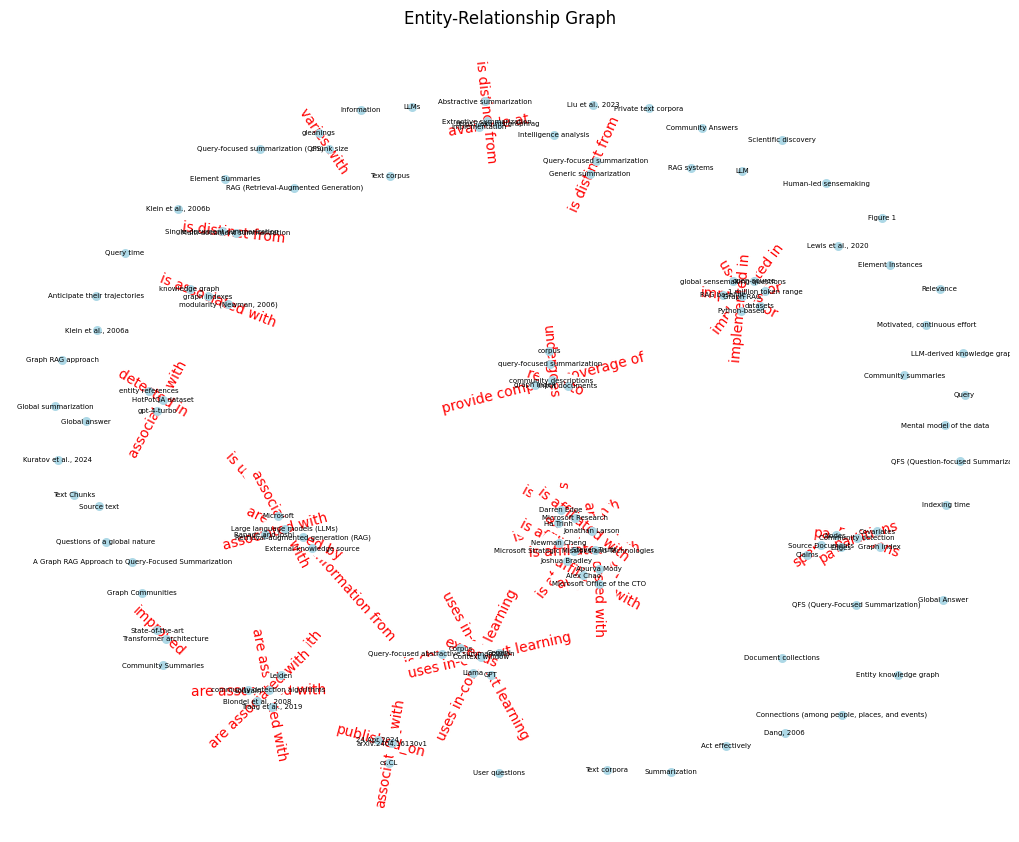

In [12]:
import matplotlib.pyplot as plt
pos = nx.spring_layout(graph)
labels = nx.get_edge_attributes(graph, 'label')

plt.figure(figsize=(10, 8))
nx.draw(graph, pos, with_labels=True, node_color='lightblue', node_size=30, font_size=5, edge_color='gray')
nx.draw_networkx_edge_labels(graph, pos, edge_labels=labels, font_color='red')
plt.title("Entity-Relationship Graph")
plt.show()

In [13]:
import igraph as ig # Convert to igraph for Leiden algorithm

def communities_detection(graph):
    """
      Detects communities (clusters of related entities) in the graph using the Leiden algorithm.

      Inputs:
        graph (networkx.Graph): The knowledge graph.
      Output:
        List of communities, each a list of entity names.
    """
    communities = []
    index = 0
    for component in nx.connected_components(graph):
        ############### Your Code - 30 pts #############################
        print(f"Component index {index} of {len(list(nx.connected_components(graph)))}:")
        # TODO

        subgraph = graph.subgraph(component)
        if len(component) > 1:  # Only detect communities for non-singletons
            try:
                ## Method 1
                # # Convert to igraph for Leiden algorithm
                # ig_graph = ig.Graph.from_networkx(subgraph)
                # partition = algorithms.leiden(ig_graph)
                # for community in partition.communities:
                #     communities.append([ig_graph.vs[node]['name'] for node in community])

                ## Method 2
                # Convert to igraph for Leiden algorithm
                ig_graph = ig.Graph.from_networkx(subgraph)
                leiden_communities = ig_graph.community_leiden().membership

                # Group nodes by community
                comm_dict = {}
                for node_idx, comm_id in enumerate(leiden_communities):
                    node_name = ig_graph.vs[node_idx]["name"]
                    comm_dict.setdefault(comm_id, []).append(node_name)

                communities.extend(comm_dict.values())


            except Exception as e:
                print(f"Error processing community {index}: {str(e)}")
                communities.append(list(component))
        else:
            communities.append(list(component))

        index += 1
    #     #######################################################
    return communities

communities = communities_detection(graph)

Component index 0 of 65:
Error processing community 0: 'Attribute does not exist'
Component index 1 of 65:
Component index 2 of 65:
Error processing community 2: 'Attribute does not exist'
Component index 3 of 65:
Component index 4 of 65:
Component index 5 of 65:
Component index 6 of 65:
Component index 7 of 65:
Component index 8 of 65:
Component index 9 of 65:
Component index 10 of 65:
Component index 11 of 65:
Component index 12 of 65:
Component index 13 of 65:
Component index 14 of 65:
Component index 15 of 65:
Error processing community 15: 'Attribute does not exist'
Component index 16 of 65:
Error processing community 16: 'Attribute does not exist'
Component index 17 of 65:
Component index 18 of 65:
Component index 19 of 65:
Error processing community 19: 'Attribute does not exist'
Component index 20 of 65:
Error processing community 20: 'Attribute does not exist'
Component index 21 of 65:
Component index 22 of 65:
Component index 23 of 65:
Component index 24 of 65:
Component inde

`4. Graph Communities → Community Summaries`

  summarize each detected community.

In [14]:
def communities_summerization(communities, graph):
    """
      Creates a textual summary for each community based on its entities and their relationships.
      Inputs:
        communities (list of list): Communities detected from the graph.
        graph (networkx.Graph): The knowledge graph with edges and labels.
      Output:
        List of string summaries for each community.
    """
    community_summaries = []
    for index, community in enumerate(communities):
        ############### Your Code - 10 pts #############################
        print(f"Summarize Community index {index} of {len(communities)}:")
        # TODO

        # Collect community relationships
        relationships = []
        for u, v, data in graph.edges(data=True, nbunch=community):
            relationships.append(f"{u} --[{data['label']}]-- {v}")

        # Prepare input for summarization
        entities_str = ", ".join(community)
        relationships_str = "\n".join(f"- {rel}" for rel in relationships)
        input_text = f"Entities: {entities_str}\nRelationships:\n{relationships_str}"

        # Generate summary
        # prompt = f"""
        # Summarize the following community of related entities.
        # Provide a concise summary that explains how these entities are related and what this community represents as a whole.
        # """
        # prompt = (
        #     "Given the following sub-graph, write a concise (≤3 sentences) "
        #     "description of the central theme or topic that links these entities."
        # )
        prompt = "Summarize the key relationships and connections between these entities in 1-2 sentences:" # or 'into a coherent paragraph.'

        summary = get_response(prompt, input_text)
        community_summaries.append(summary)

        #######################################################
    return community_summaries

community_summaries = communities_summerization(communities, graph)

Summarize Community index 0 of 65:
Summarize Community index 1 of 65:
Summarize Community index 2 of 65:
Summarize Community index 3 of 65:
Summarize Community index 4 of 65:
Summarize Community index 5 of 65:
Summarize Community index 6 of 65:
Summarize Community index 7 of 65:
Summarize Community index 8 of 65:
Summarize Community index 9 of 65:
Summarize Community index 10 of 65:
Summarize Community index 11 of 65:
Summarize Community index 12 of 65:
Summarize Community index 13 of 65:
Summarize Community index 14 of 65:
Summarize Community index 15 of 65:
Summarize Community index 16 of 65:
Summarize Community index 17 of 65:
Summarize Community index 18 of 65:
Summarize Community index 19 of 65:
Summarize Community index 20 of 65:
Summarize Community index 21 of 65:
Summarize Community index 22 of 65:
Summarize Community index 23 of 65:
Summarize Community index 24 of 65:
Summarize Community index 25 of 65:
Summarize Community index 26 of 65:
Summarize Community index 27 of 65:
Su

`6. Community Summaries → Community Answers → Global Answer`

  Finally, we generate answers from community summaries and combine them into a final global answer.

In [15]:
def generate_final_answer(community_summaries, query):
    """
      Answers a query by using each community summary, then aggregates all answers.
      Inputs:
        community_summaries (list of str): Summaries of each community.
        query (str): The user query.
      Output:
        A final answer string synthesized from all community-based answers.
    """
    intermediate_answers = []
    for index, summary in enumerate(community_summaries):
        ############### Your Code - 10 pts #############################
        print(f"Summary index {index} of {len(community_summaries)}:")
        # TODO

        # prompt = f"Based ONLY on the following context, answer the query. If the context is not relevant or does not contain the answer, say so. Query: {query}\n"
        # prompt = f"""
        # Based on the following community summary, answer this query:
        # Query: {query}

        # Provide a concise answer that addresses the query using only information
        # from this community summary. If the summary doesn't contain relevant
        # information, state that explicitly.
        # """

        prompt = f"Using only the following information, answer this query: '{query}'. If the information is irrelevant, say so."

        answer = get_response(prompt, summary)
        intermediate_answers.append(answer)
        print(f"Intermediate answer: {answer}")

    # Combine answers into final response
    combined_answers = "\n".join(
        f"Answer {i}: {ans}" for i, ans in enumerate(intermediate_answers)
    )
    # final_prompt = f"Synthesize the following information into a single, comprehensive answer to the query: '{query}'.\n\nInformation: {combined_answers}"
    # final_prompt = f"""
    # Combine the following partial answers to create a comprehensive final answer
    # to the query: {query}

    # Partial Answers:
    # {combined_answers}

    # Synthesize a coherent final answer that incorporates all relevant information
    # from the partial answers, removing any redundancy.
    # """
    # final_prompt = (
    #     "You are given several short answers to the same question. "
    #     "Merge them into one coherent paragraph, removing duplicates "
    #     "and contradictions, and keep it concise:\n\n" +
    #     f"query: {query} \n {combined_answers}"
    # )
    final_prompt = f"Combine these answers to comprehensively address the query '{query}':\n{combined_answers}"

    final_answer = get_response(final_prompt, "")
        #######################################################

    return final_answer

query = "What problem does Graph RAG aim to solve that traditional RAG and QFS methods cannot?"
print('Query:', query)
final_answer = generate_final_answer(community_summaries, query)
print("Answer: ", final_answer)

Query: What problem does Graph RAG aim to solve that traditional RAG and QFS methods cannot?
Summary index 0 of 65:
Intermediate answer: The information provided does not mention Graph RAG, traditional RAG, or QFS methods, and therefore does not answer the query.
Summary index 1 of 65:
Intermediate answer: Graph RAG aims to solve the problem of capturing and utilizing relational information between entities during query-focused summarization, which traditional RAG and QFS methods cannot effectively handle.
Summary index 2 of 65:
Intermediate answer: Graph RAG aims to solve the problem of inefficient information retrieval in traditional RAG and QFS methods by leveraging graph structures to better capture and navigate relationships between entities, thereby improving the relevance and efficiency of retrieved information.
Summary index 3 of 65:
Intermediate answer: Graph RAG aims to solve the problem of limited context retention and inefficient information retrieval in traditional RAG and

### **For answering the following questions we apply two methods:**
- **First, we answer them using our own understanding from the provided paper.**
- **Second, answer them using the model that we implemented.**

#### Analyze the proposed method for these questions. `10 pts`

- What problem does Graph RAG aim to solve that traditional RAG and QFS methods cannot? *Graph RAG aims to solve the problem of answering global questions that require understanding of an entire text corpus, which traditional RAG and QFS methods struggle with. Traditional RAG works well for localized questions but fails on global questions like "What are the main themes in the dataset?" because it can't synthesize information across the entire corpus. QFS methods, meanwhile, don't scale to the large quantities of text that RAG systems typically handle.*

    * **Graph RAG** aims to solve the challenge of answering *global questions* over an entire corpus—such as “What are the main themes in this dataset?”—that cannot be addressed by traditional RAG (retrieval-augmented generation) or Query-Focused Summarization (QFS) methods.

    * **Traditional RAG**: Is designed for “local” questions—where answers exist within discrete, retrievable text chunks—but fails when questions require synthesizing knowledge spanning the entire dataset.
    * **QFS methods**: Can theoretically answer such global questions but fail to scale to corpora of the size that RAG systems routinely handle (e.g., millions of tokens).

**Graph RAG combines both strengths**: it scales to large corpora (like RAG) and supports global summarization (like QFS) by organizing the corpus into a knowledge graph and using community detection and summarization.

- How does the Graph RAG architecture overcome the limitations of LLM context windows? *Graph RAG overcomes LLM context window limitations by:*
    1. Creating a hierarchical graph structure that organizes information
    2. Generating community summaries at different levels of granularity
    3. Using a map-reduce approach where partial answers are generated from community summaries and then combined
    *This allows processing of large corpora without needing to fit everything into a single context window.*

    In other words, **Graph RAG** overcomes context window limitations by:

    * Building a hierarchical knowledge graph from the corpus.
    * Using community detection to partition the graph into modular, closely-related groups of entities (“communities”).
    * Generating summaries for each community at multiple levels.
    * At query time, it summarizes relevant community summaries in a *map-reduce* fashion—allowing the LLM to process only manageable, context-sized chunks at each stage, rather than the entire corpus at once.

- What are the key steps in the Graph RAG pipeline, and how are they distributed between indexing time and query time? *The answer is depicted in the following figure from the paper:* ![GraphRAG](https://drive.google.com/uc?export=view&id=16Pv1vt_yY6u9ARodmnkbRmQttcpnjB18)
    
    **Indexing time:**

    1. **Text extraction and chunking (Document chunking):** Source documents are split into text chunks.
    2. **Element extraction(Entity and relationship extraction):** LLMs extract entities, relationships, and claims from each chunk.
    3. **Element summarization:** Instance-level summaries for each entity, relationship, or claim.
    4. **Graph construction:** Nodes (entities), edges (relationships), and covariates (claims) are structured into a graph.
    5. **Community detection:** Algorithms (like Leiden or Louvain) partition the graph into communities.
    6. **Community summarization:** LLM generates summaries for each community (at various levels).

    **Query time:**
    7. **Query processing & Community answer generation:** For a user query, each community summary is used to generate a partial, query-focused answer.
    8. **Global answer generation:** These partial answers are then summarized (again, via LLM) into a final, global answer for the user.


- How does Graph RAG differ from previous QFS or graph-based retrieval approaches? *Graph RAG differs by:*
    * Unlike standard QFS, Graph RAG is explicitly **designed to scale**: it uses hierarchical graph partitioning and map-reduce summarization for very large corpora.
    * Unlike prior graph-based retrieval or RAG systems, which may use graphs for structured retrieval or traversal, **Graph RAG leverages the inherent modularity of graphs**—specifically, the use of community detection to enable divide-and-conquer summarization.
    * Prior approaches may use knowledge graphs for retrieval, but don’t use community detection and hierarchical summarization to support efficient global queries over massive corpora.

    In summary:
        1. Combining strengths of both RAG and QFS approaches
        2. Using graph modularity to create thematic partitions
        3. Generating hierarchical community summaries
        4. Scaling to much larger corpora than traditional QFS
        5. Focusing on global sensemaking rather than just fact retrieval

- What role do community detection algorithms (e.g., Leiden or Louvain) play in the Graph RAG framework? *Community detection algorithms:*
    1. Identify groups of closely related entities
    2. Create a hierarchical structure of communities
    3. Enable divide-and-conquer summarization
    4. Provide thematic organization of the corpus
    5. Allow for efficient query processing at different levels of granularity

  In fact, Community detection algorithms partition the knowledge graph into groups (communities) of closely-related entities. This modular partitioning allows the LLM to generate summaries for each community independently. It supports hierarchical summarization: communities can be split recursively into sub-communities at different levels, allowing for fine-to-coarse summarization depending on the query’s scope. Partitioning enables *divide-and-conquer* summarization, overcoming context window limits and improving efficiency.

- How does the performance of Graph RAG scale with increasing corpus size (e.g., 1M tokens)? *The paper shows Graph RAG works well with corpora in the 1 million token range. The hierarchical community structure allows it to scale by:*
    1. Parallel processing of communities
    2. Reusing pre-generated summaries
    3. Processing information at appropriate levels of granularity
    
  The root-level summaries (C0) require significantly fewer tokens (97% fewer) than processing all text chunks.

  The system was evaluated on datasets of \~1M tokens. Results show **Graph RAG scales efficiently**:

    * Outperforms naive RAG in both comprehensiveness and diversity of answers.
    * Intermediate and low-level community summaries enable higher answer quality with lower token cost compared to summarizing all source texts.
    * For example, low-level community summaries reduced required context tokens by 26–33%, while root-level summaries reduced them by over 97%—yet still performed much better than naive RAG.

- What kind of summaries are generated during each stage of the Graph RAG pipeline, and how are they used?
    1. Entity/relationship summaries: From text chunks. Each entity, relationship, or claim extracted from text chunks is summarized.
    2. Community summaries: For each detected community. Summaries for each detected community (group of related elements). These are *independently useful* for understanding dataset themes and are used for answering queries.
    3. Partial answers (Community Answers): Generated from community summaries in response to queries. For a specific query, each community summary generates a partial answer.
    4. Global answers: Synthesized from partial answers. All partial answers are further summarized into a single, final answer returned to the user.

- Why is the distinction between ‘local’ and ‘global’ queries important in the design of Graph RAG? *Local queries can be answered from a few relevant documents, while global queries require understanding patterns and themes across the entire corpus. Graph RAG is specifically designed to handle global queries that traditional RAG can't address effectively.*

    * **Local queries** can be answered by retrieving a small, relevant subset of the corpus—this is where traditional RAG excels.
    * **Global queries** require synthesizing information spanning the entire dataset, which cannot be satisfied by retrieving a few chunks.
    * Graph RAG’s architecture specifically supports global queries by enabling the summarization of the whole corpus in a scalable way, using its modular, hierarchical structure. This distinction ensures each query is answered using the most efficient and appropriate method.

- How does entity extraction using GPT-4-turbo vary with chunk sizes in the HotPotQA dataset, as shown in Figure 2? *The Figure in the paper shows that with larger chunk sizes, fewer entities are extracted initially, but using self-reflection techniques can recover most of the missing entities while still benefiting from the efficiency of larger chunks.*
    * **Smaller chunk sizes (e.g., 600 tokens)** result in almost twice as many entity references being detected in a single extraction round compared to larger chunk sizes (e.g., 2400 tokens).
    * **Recall degrades with larger chunks:** The LLM is more likely to miss entities when asked to process longer input, due to context window limitations and “lost in the middle” effects.
    * The extraction process can be improved by using multiple “gleaning” rounds to recover missed entities, allowing for larger chunks without as much loss in quality.

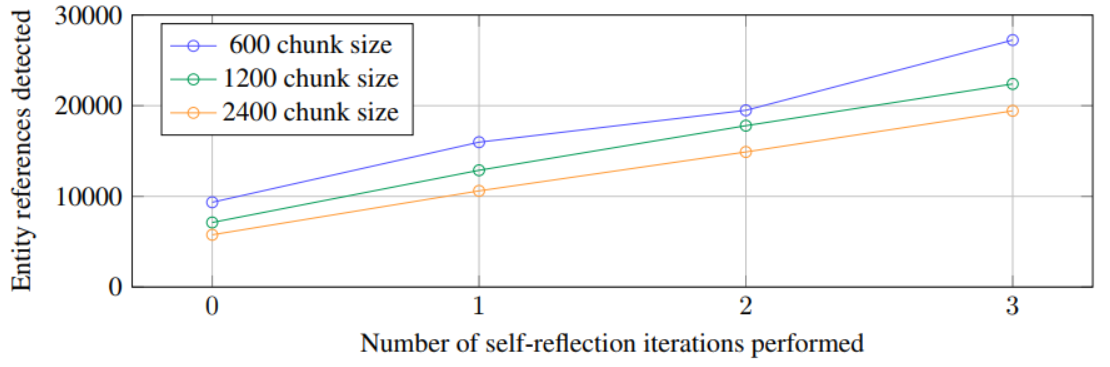

- Why do the authors claim that query-focused abstractive summarization is more appropriate than retrieval-based generation for global questions? *Because global questions require synthesizing information across many documents rather than retrieving specific facts. Abstractive summarization can identify patterns, themes, and high-level insights that aren't explicitly stated in any single document.*
    * Retrieval-based generation (i.e., RAG) assumes answers are *localized* within retrievable text chunks.
    * **Global questions** require *synthesizing and summarizing* information from across the corpus, not just retrieving and copying.
    * Abstractive summarization can aggregate, condense, and rephrase information from many sources, creating a coherent and comprehensive answer—something retrieval alone cannot achieve for global sensemaking questions.

- In what ways does the modularity of graphs enable better summarization in the context of large corpora? *Modularity allows:*
    1. Natural partitioning of information into thematic groups
    2. Hierarchical organization of concepts
    3. Efficient summarization at different levels of detail
    4. Better preservation of relationships between concepts

    In other words, Modularity allows partitioning the data into communities of related entities, each of which can be summarized independently and efficiently. Enables hierarchical summarization: summaries at different levels (fine or coarse) depending on the required detail or scope. Prevents context window overflow: Each LLM summarization step operates within manageable, non-overlapping chunks. Reduces redundancy and enables focused, high-coverage answers to broad questions.

- How does Graph RAG contribute to the broader goal of sensemaking in domains like scientific discovery or intelligence analysis? *Graph RAG supports sensemaking by:*
    1. Revealing connections between concepts across large corpora
    2. Identifying emerging themes and trends
    3. Helping analysts understand complex relationships
    4. Providing comprehensive answers to broad questions

  This is particularly valuable in domains like scientific research where understanding interdisciplinary connections is crucial.

  Sensemaking requires integrating and reasoning over large, complex document collections to draw high-level insights not explicit in any single source. Graph RAG supports *iterative, exploratory, and comprehensive* querying—helping users build and refine mental models of the data. Its ability to answer both local and global queries, generate hierarchical summaries, and facilitate “drill down” or “roll up” navigation aligns well with the real-world workflows of domains like scientific research or intelligence analysis, where understanding connections and synthesizing broad patterns is crucial.

### Answering above questions using our implemented method

In [17]:
questions = [   "What problem does Graph RAG aim to solve that traditional RAG and QFS methods cannot?",
    "How does the Graph RAG architecture overcome the limitations of LLM context windows?",
    "What are the key steps in the Graph RAG pipeline, and how are they distributed between indexing time and query time?",
    "How does Graph RAG differ from previous QFS or graph-based retrieval approaches?",
    "What role do community detection algorithms (e.g., Leiden or Louvain) play in the Graph RAG framework?",
    "How does the performance of Graph RAG scale with increasing corpus size (e.g., 1M tokens)?",
    "What kind of summaries are generated during each stage of the Graph RAG pipeline, and how are they used?",
    "Why is the distinction between ‘local’ and ‘global’ queries important in the design of Graph RAG?",
    "How does entity extraction using GPT-4-turbo vary with chunk sizes in the HotPotQA dataset, as shown in Figure 2?",
    "Why do the authors claim that query-focused abstractive summarization is more appropriate than retrieval-based generation for global questions?",
    "In what ways does the modularity of graphs enable better summarization in the context of large corpora?",
    "How does Graph RAG contribute to the broader goal of sensemaking in domains like scientific discovery or intelligence analysis?"
]

print("Analyze the proposed method for these questions. (Answering above questions using our implemented method)")
print("\n--------------------------------------------------------\n")
i = 1
for question in questions:
    print(f'Question {i}: ', question)
    final_answer = generate_final_answer(community_summaries, question)
    print("Answer: ", final_answer)
    print("\n--------------------------------------------------------\n")
    i += 1

Analyze the proposed method for these questions. (Answering above questions using our implemented method)

--------------------------------------------------------

Question 1:  What problem does Graph RAG aim to solve that traditional RAG and QFS methods cannot?
Summary index 0 of 65:
Intermediate answer: The information provided does not mention Graph RAG, traditional RAG, or QFS methods, and therefore does not answer the query.
Summary index 1 of 65:
Intermediate answer: Graph RAG aims to solve the problem of capturing and utilizing contextual relationships between entities during query-focused summarization, which traditional RAG and QFS methods cannot effectively handle.
Summary index 2 of 65:
Intermediate answer: Graph RAG aims to solve the problem of inefficient information retrieval in traditional RAG and QFS methods by leveraging graph structures to better capture and navigate relationships between entities, thereby improving the relevance and efficiency of retrieved informati

OutOfMemoryError: CUDA out of memory. Tried to allocate 5.78 GiB. GPU 0 has a total capacity of 14.74 GiB of which 5.11 GiB is free. Process 9969 has 9.63 GiB memory in use. Of the allocated memory 8.54 GiB is allocated by PyTorch, and 988.83 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

### **Becasue we encontered the "*OutOfMemoryError: CUDA out of memory* " error we try anwering the questions with smaller model (Qwen3-1.7B) and less generated tokens to prevent the "*OutOfMemoryError: CUDA out of memory* error** " error.

In [5]:
import torch

del model
del tokenizer

if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer

# model_name = "Qwen/Qwen3-4B"
model_name = "Qwen/Qwen3-1.7B"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype="auto",
    device_map="auto"
)

def get_response(prompt, content):
    messages = [
        {"role": "user", "content": content + ' Do not include any additional and irrelevant information. \t' + prompt}
    ]
    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False # Switches between thinking and non-thinking modes. Default is True.
    )
    model_inputs = tokenizer([text], return_tensors="pt").to(model.device)

    generated_ids = model.generate(
        **model_inputs,
        # max_new_tokens=32768
        max_new_tokens=3000 # avoiding "OutOfMemoryError: CUDA out of memory"
    )
    output_ids = generated_ids[0][len(model_inputs.input_ids[0]):].tolist()


    response = tokenizer.decode(output_ids[0:], skip_special_tokens=True).strip("\n")
    return response

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/622M [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

In [ ]:
def generate_final_answer(community_summaries, query):
    """
      Answers a query by using each community summary, then aggregates all answers.
      Inputs:
        community_summaries (list of str): Summaries of each community.
        query (str): The user query.
      Output:
        A final answer string synthesized from all community-based answers.
    """
    intermediate_answers = []
    for index, summary in enumerate(community_summaries):
        ############### Your Code - 10 pts #############################
        print(f"Summary index {index} of {len(community_summaries)}:")
        # TODO

        prompt = f"Using only the following information, answer this query: '{query}'. If the information is irrelevant, say so. Answer only in 1-2 paragraphs"

        answer = get_response(prompt, summary)
        if answer not in intermediate_answers:
            intermediate_answers.append(answer)
        print(f"Intermediate answer: {answer}")

    # Combine answers into final response
    combined_answers = "\n".join(
        f"Answer {i}: {ans}" for i, ans in enumerate(intermediate_answers)
    )

    final_prompt = f"Combine these answers to comprehensively address the query '{query}':\n{combined_answers}"

    final_answer = get_response(final_prompt, "")
        #######################################################

    return final_answer

In [4]:
questions = [   "What problem does Graph RAG aim to solve that traditional RAG and QFS methods cannot?",
    "How does the Graph RAG architecture overcome the limitations of LLM context windows?",
    "What are the key steps in the Graph RAG pipeline, and how are they distributed between indexing time and query time?",
    "How does Graph RAG differ from previous QFS or graph-based retrieval approaches?",
    "What role do community detection algorithms (e.g., Leiden or Louvain) play in the Graph RAG framework?",
    "How does the performance of Graph RAG scale with increasing corpus size (e.g., 1M tokens)?",
    "What kind of summaries are generated during each stage of the Graph RAG pipeline, and how are they used?",
    "Why is the distinction between ‘local’ and ‘global’ queries important in the design of Graph RAG?",
    "How does entity extraction using GPT-4-turbo vary with chunk sizes in the HotPotQA dataset, as shown in Figure 2?",
    "Why do the authors claim that query-focused abstractive summarization is more appropriate than retrieval-based generation for global questions?",
    "In what ways does the modularity of graphs enable better summarization in the context of large corpora?",
    "How does Graph RAG contribute to the broader goal of sensemaking in domains like scientific discovery or intelligence analysis?"
]

print("Analyze the proposed method for these questions. (Answering above questions using our implemented method)")
print("\n--------------------------------------------------------\n")
i = 3
for question in questions[2:]:
    print(f'Question {i}: ', question)
    final_answer = generate_final_answer(community_summaries, question)
    print("Answer: ", final_answer)
    print("\n--------------------------------------------------------\n")
    i += 1

Analyze the proposed method for these questions. (Answering above questions using our implemented method)

--------------------------------------------------------

Question 3:  What are the key steps in the Graph RAG pipeline, and how are they distributed between indexing time and query time?
Summary index 0 of 65:
Intermediate answer: The Graph RAG pipeline involves two main stages: indexing and querying. During indexing, the graph is processed to create a structured representation, including nodes, edges, and metadata, which is stored in a graph database. This step ensures that the graph is preprocessed and ready for efficient querying. Querying involves retrieving and combining information from the graph, often using natural language processing to understand the query and then matching it to the pre-indexed graph data. The indexing process is typically done once, while querying is performed dynamically, distributing the computational load between the two stages.
Summary index 1 of 